# Actividad 4 — Diagnóstico integrador

**Técnicas de Análisis Estadístico de Modelos Supervisados**
**Datos:** base depurada de la Actividad 1 (*Mice Protein Expression*, 1.077 réplicas de 72 ratones).

**Objetivo del notebook:** integrar las Actividades 1, 2 y 3 en un solo recorrido, y evaluar qué tan confiables y
robustos son los modelos finales de regresión y de clasificación, bajo qué condiciones funcionan o fallan, y qué
decisiones pueden respaldar. Este notebook no repite las búsquedas de hiperparámetros: reajusta los modelos finales
con los valores que ya se eligieron y reúne sus diagnósticos.

| Sección | Contenido |
|---|---|
| 0 | Preparación del entorno |
| 1 | El problema y el hilo del proyecto |
| 2 | Los datos: depuración y unidad experimental |
| 3 | De la exploración a las decisiones de modelado |
| 4 | Diagnóstico del modelo de regresión |
| 5 | Diagnóstico del modelo de clasificación |
| 6 | Síntesis del proceso analítico |
| 7 | Análisis crítico y ético |
| 8 | Conclusión y mensaje para el usuario de los resultados |

## 0. Preparación del entorno

In [1]:
# Ejecución en Google Colab: clona el repositorio, instala las versiones del proyecto
# y genera la base depurada. En una ejecución local esta celda no hace nada.
# La primera ejecución instala las librerías y reinicia el entorno, por lo que la celda
# se ejecuta dos veces.
import os, sys

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    import sklearn
    if sklearn.__version__ != "1.9.1":
        !pip install -q numpy==2.5.3 pandas==3.0.6 scikit-learn==1.9.1 scipy==1.18.1 statsmodels==0.15.0 matplotlib==3.11.2 seaborn==0.13.2 pyarrow==25.0.1 xlrd==2.0.2
        print("Versiones instaladas. El entorno se reinicia: ejecutar de nuevo esta celda.")
        os.kill(os.getpid(), 9)

    RAIZ_COLAB = "/content/mice-supervisado"
    if not os.path.exists(RAIZ_COLAB):
        !git clone -q https://github.com/Juanhv24/mice-supervisado.git {RAIZ_COLAB}
    os.chdir(f"{RAIZ_COLAB}/notebooks")
    sys.path.insert(0, f"{RAIZ_COLAB}/src")
    os.environ["PYTHONPATH"] = f"{RAIZ_COLAB}/src"

    # La base depurada no se versiona: se descarga el archivo de UCI y se ejecuta la Actividad 1
    if not os.path.exists(f"{RAIZ_COLAB}/datos/procesados/mice_depurado.parquet"):
        !python ../scripts/descargar_datos.py
        !jupyter nbconvert --to notebook --execute 01_eda.ipynb --output /tmp/01_eda_colab.ipynb

In [2]:
# Librerías externas
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Regresión inferencial y diagnóstico
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

# Partición, validación y preprocesamiento
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, GroupKFold,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder, label_binarize
from sklearn.impute import KNNImputer

# Modelos finales de las Actividades 2 y 3
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

# Métricas
from sklearn.metrics import (r2_score, root_mean_squared_error, mean_absolute_error,
                             accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, roc_curve,
                             log_loss, brier_score_loss, ConfusionMatrixDisplay)

# Paquete del proyecto: semilla, rutas y funciones de carga
from mice_supervisado.config import SEMILLA, ruta_figuras
from mice_supervisado.datos import cargar_depurados

# Configuración de la sesión; se silencia el aviso de scikit-learn sobre el parámetro probability de SVC,
# también en los procesos paralelos
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 90)
FIGURAS = ruta_figuras(4)

In [3]:
# Base depurada de la Actividad 1 y variables de los dos problemas
df = cargar_depurados()

GRUPO = "raton"
DISENO = ["Genotype", "Treatment", "Behavior"]
PROTEINAS = [col for col in df.columns if col.endswith("_N")]

# Regresión (Actividad 2)
OBJETIVO_REG = "pERK_N"
PREDICTORES_M1 = ["DYRK1A_N", "BRAF_N", "ITSN1_N"]
PROTEINAS_M2 = [p for p in PROTEINAS if p != OBJETIVO_REG]

# Clasificación (Actividad 3)
OBJETIVO_CLA = "class"
CLASES = sorted(df[OBJETIVO_CLA].unique())

assert df.shape == (1077, 83)
assert len(PROTEINAS) == 76 and len(CLASES) == 8
assert not set(DISENO + [OBJETIVO_CLA, GRUPO]) & set(PROTEINAS)

print(f"Base: {df.shape} | ratones: {df[GRUPO].nunique()} | proteínas: {len(PROTEINAS)} | clases: {len(CLASES)}")

Base: (1077, 83) | ratones: 72 | proteínas: 76 | clases: 8


## 1. El problema y el hilo del proyecto

Los ratones Ts65Dn son un modelo murino del síndrome de Down que presenta déficits de aprendizaje (Reeves et al.,
1995). En el experimento que originó esta base, ratones control y Ts65Dn se sometieron a un condicionamiento de miedo
al contexto: los del grupo CS fueron estimulados para aprender y los del grupo SC sirvieron como control sin
aprendizaje. Los ratones Ts65Dn tratados con salina no lograron aprender, mientras que la memantina rescató su
aprendizaje (Ahmed et al., 2015). Luego, en la corteza de cada animal se midió la expresión de 77 proteínas, muchas
de ellas pertenecientes a vías de señalización asociadas a la plasticidad sináptica y la memoria (Higuera et al.,
2015; Sweatt, 2004).

A partir de esta base, el proyecto respondió dos preguntas. En la Actividad 2, **¿qué explica y qué tan bien se
predice el nivel de `pERK_N`**, la forma activa de una quinasa central en la memoria? En la Actividad 3, **¿se puede
identificar la condición experimental de un ratón** (genotipo, conducta y tratamiento) **a partir de su perfil de
proteínas?**

Sin embargo, el hilo que une las tres actividades no es un modelo, sino una característica de los datos: cada ratón
aporta 15 réplicas, de modo que las 1.077 filas no son 1.077 observaciones independientes. Tratar las réplicas como
individuos se conoce como pseudorreplicación, y lleva a conclusiones con una confianza que los datos no respaldan
(Hurlbert, 1984; Lazic, 2010). Por eso, este notebook sigue esa idea de principio a fin: primero se mide la
dependencia entre réplicas (sección 2), luego se muestra cómo cambió las decisiones de modelado (sección 3), después
se evalúa su efecto en la regresión (sección 4) y en la clasificación (sección 5), y por último se discute qué
implica para el uso responsable de los resultados (secciones 6 a 8).

## 2. Los datos: depuración y unidad experimental

### 2.1 De la base original a la base depurada

La base original tiene 1.080 réplicas, 77 proteínas y las variables del diseño. En la Actividad 1 se tomaron diez
decisiones de depuración, documentadas en `docs/bitacora_decisiones.md`; las que cambiaron la base fueron tres:

| Decisión | Registros afectados | Justificación |
|---|---|---|
| Eliminar la columna `pS6_N` | 1 columna | Sus valores eran idénticos a los de `ARC_N` en todas las filas |
| Eliminar tres réplicas del ratón 3426 | 3 filas | Tenían más de la mitad de las proteínas sin medir; el ratón se conserva con 12 réplicas |
| Reemplazar por faltante un valor negativo de `RRP1_N` | 1 celda | Una cantidad de proteína no puede ser negativa |

En cambio, los valores extremos se conservaron, porque se repiten en las réplicas del mismo ratón y, por tanto,
reflejan al individuo y no un error de medición; y la imputación, el escalado y la transformación logarítmica se
dejaron para el `Pipeline` de cada modelo, de modo que se ajusten solo con los ratones de entrenamiento (Kuhn &
Johnson, 2019).

In [4]:
# Estructura de la base: filas frente a individuos
replicas = df.groupby(GRUPO).size()
estructura = pd.Series({
    "Réplicas (filas)": len(df),
    "Ratones (individuos)": df[GRUPO].nunique(),
    "Réplicas por ratón (mínimo – máximo)": f"{replicas.min()} – {replicas.max()}",
    "Ratones por clase (mínimo – máximo)": "{} – {}".format(
        *df.groupby(OBJETIVO_CLA, observed=True)[GRUPO].nunique().agg(["min", "max"])),
    "Proteínas con faltantes": int((df[PROTEINAS].isna().sum() > 0).sum()),
    "Celdas faltantes en proteínas": int(df[PROTEINAS].isna().sum().sum()),
}, name="Valor")
estructura.to_frame()

,Valor
Réplicas (filas),1077
Ratones (individuos),72
Réplicas por ratón (mínimo – máximo),12 – 15
Ratones por clase (mínimo – máximo),7 – 10
Proteínas con faltantes,10
Celdas faltantes en proteínas,1268


**Interpretación:** la base depurada tiene 1.077 réplicas, pero solo 72 individuos, con entre 12 y 15 réplicas por
ratón y entre 7 y 10 ratones por clase. Además, quedan 1.268 celdas faltantes en 10 proteínas, casi todas en las 8
proteínas que no se midieron en ninguna réplica de algunos ratones. En consecuencia, el número de filas da una idea
exagerada de la cantidad de información disponible, como se cuantifica a continuación.

### 2.2 ¿Cuánta información independiente hay?

Si las réplicas de un ratón se parecen mucho entre sí, cada réplica adicional aporta poca información nueva. La
correlación intraclase (ICC) mide ese parecido como la proporción de la varianza de una proteína que está entre
ratones y no dentro de ellos. A partir de ella, el efecto de diseño, 1 + (m − 1) · ICC, indica cuántas veces se
subestima la varianza al suponer independencia, y el tamaño efectivo es el número de réplicas dividido entre ese
efecto (Cameron & Miller, 2015). El ICC se calcula de dos formas: sobre los valores de cada proteína y después de
restar la media de su clase, para descontar las diferencias que se deben a la condición experimental.

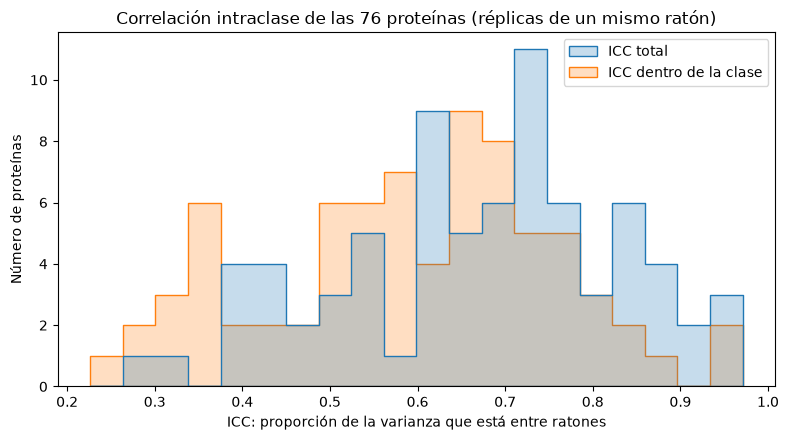

,Mediana del ICC,"Proteínas con ICC > 0,5",Efecto de diseño,Tamaño efectivo
ICC total,0.7,63,10.77,100.04
ICC dentro de la clase,0.6,54,9.43,114.16


In [5]:
def correlacion_intraclase(valores, grupos):
    """Correlación intraclase de un factor (ANOVA): proporción de la varianza que está entre ratones."""
    datos = pd.DataFrame({"y": valores, "g": grupos}).dropna()
    tamanos = datos.groupby("g")["y"].size()
    medias = datos.groupby("g")["y"].mean()
    n, k = len(datos), len(tamanos)
    n0 = (n - (tamanos ** 2).sum() / n) / (k - 1)                      # tamaño medio de grupo ajustado
    cm_entre = (tamanos * (medias - datos["y"].mean()) ** 2).sum() / (k - 1)
    cm_dentro = ((datos["y"] - datos["g"].map(medias)) ** 2).sum() / (n - k)
    return (cm_entre - cm_dentro) / (cm_entre + (n0 - 1) * cm_dentro)


# ICC de cada proteína en escala log: total y después de descontar la media de su clase
log_proteinas = np.log(df[PROTEINAS])
centradas = log_proteinas - log_proteinas.groupby(df[OBJETIVO_CLA], observed=True).transform("mean")
icc = pd.DataFrame({
    "ICC total": [correlacion_intraclase(log_proteinas[p], df[GRUPO]) for p in PROTEINAS],
    "ICC dentro de la clase": [correlacion_intraclase(centradas[p], df[GRUPO]) for p in PROTEINAS],
}, index=PROTEINAS)

# Tamaño efectivo: n / (1 + (m - 1) · ICC), con m = 15 réplicas por ratón
m = replicas.mean()
resumen_icc = pd.DataFrame({
    "Mediana del ICC": icc.median(),
    "Proteínas con ICC > 0,5": (icc > 0.5).sum(),
    "Efecto de diseño": 1 + (m - 1) * icc.median(),
    "Tamaño efectivo": len(df) / (1 + (m - 1) * icc.median()),
}).round(2)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(icc, bins=20, element="step", ax=ax)
ax.set(title="Correlación intraclase de las 76 proteínas (réplicas de un mismo ratón)",
       xlabel="ICC: proporción de la varianza que está entre ratones", ylabel="Número de proteínas")
fig.tight_layout()
fig.savefig(FIGURAS / "icc_proteinas.png", dpi=150, bbox_inches="tight")
plt.show()
resumen_icc

**Interpretación:** la mediana del ICC de las 76 proteínas es 0,70, y 63 de ellas superan 0,5; es decir, en la
proteína típica, el 70 % de la varianza está entre ratones y solo el 30 % entre las réplicas de un mismo animal.
Incluso después de descontar las diferencias entre clases, la mediana es 0,60, lo que indica que el parecido entre
réplicas no se explica solo por la condición experimental, sino por el individuo.

Con estos valores, el efecto de diseño es cercano a 10, de modo que las 1.077 réplicas equivalen a entre 100 y 114
observaciones independientes, alrededor de una décima parte. Este resultado tiene dos consecuencias que se retoman en
las secciones siguientes. Por un lado, cualquier error estándar calculado como si las filas fueran independientes
subestima la incertidumbre (sección 4.1). Por otro lado, si las réplicas de un ratón se reparten entre entrenamiento
y validación, el modelo se evalúa con datos casi idénticos a los que ya vio (sección 5.1).

## 3. De la exploración a las decisiones de modelado

La exploración de la Actividad 1 dejó tres hallazgos que definieron los modelos. Primero, las proteínas se mueven en
bloques muy correlacionados, lo que anticipaba problemas de multicolinealidad. Segundo, `pERK_N` resultó una buena
variable para la regresión, porque es la forma activa de ERK, implicada en la plasticidad sináptica (Sweatt, 2004), y
porque se relaciona con proteínas con respaldo biológico: DYRK1A forma un complejo con Ras, B-Raf y MEK1 que potencia
esa cascada (Kelly & Rahmani, 2005). Tercero, la estructura de réplicas obligaba a partir los datos por ratón.

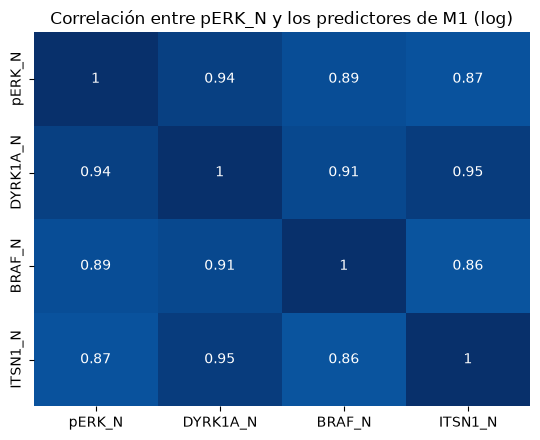

In [6]:
# Relación de pERK_N con los predictores de M1 y entre ellos (escala log, toda la base)
correlaciones = np.log(df[[OBJETIVO_REG] + PREDICTORES_M1]).corr().round(2)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(correlaciones, annot=True, cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set(title="Correlación entre pERK_N y los predictores de M1 (log)")
fig.tight_layout()
fig.savefig(FIGURAS / "correlacion_m1.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** en escala logarítmica, `pERK_N` se correlaciona con `DYRK1A_N` (0,94), `BRAF_N` (0,89) e
`ITSN1_N` (0,87), lo que respalda su uso como predictores del modelo explicativo (M1). Sin embargo, los predictores
también están muy correlacionados entre sí, entre 0,86 y 0,95, de modo que es difícil separar el aporte de cada uno.
Por eso el proyecto usó dos modelos de regresión con propósitos distintos: M1, con tres proteínas y el diseño, para
explicar, y M2, con las 75 proteínas restantes y regularización, para predecir (James et al., 2023).

In [7]:
# Misma partición de las Actividades 2 y 3: primer pliegue agrupado por ratón y estratificado por clase
sgfk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(sgfk.split(df, df[OBJETIVO_CLA], groups=df[GRUPO]))
train, test = df.iloc[idx_train], df.iloc[idx_test]
grupos_train, grupos_test = train[GRUPO], test[GRUPO]

assert set(grupos_train).isdisjoint(grupos_test)
assert test[OBJETIVO_CLA].nunique() == len(CLASES)

print(f"Entrenamiento: {len(train)} réplicas, {grupos_train.nunique()} ratones")
print(f"Prueba: {len(test)} réplicas, {grupos_test.nunique()} ratones")

Entrenamiento: 867 réplicas, 58 ratones
Prueba: 210 réplicas, 14 ratones


**Interpretación:** la partición es la misma de las Actividades 2 y 3: 58 ratones (867 réplicas) para entrenar y 14
ratones (210 réplicas) para la prueba final, sin ningún ratón compartido y con las 8 clases en ambos conjuntos. Como
agrupa por ratón, ninguna réplica de un animal de prueba interviene en el ajuste (Roberts et al., 2017). Los ratones
de prueba solo se usan al final de las secciones 4 y 5.

## 4. Diagnóstico del modelo de regresión

### 4.1 El costo de ignorar la dependencia entre réplicas

M1 explica `pERK_N` con `DYRK1A_N`, `BRAF_N`, `ITSN1_N` y las tres variables del diseño. Los coeficientes son los
mismos con cualquier método, pero su incertidumbre no: se comparan los errores estándar ordinarios, que suponen filas
independientes, con los errores agrupados por ratón, que permiten que las réplicas de un mismo animal estén
correlacionadas (Cameron & Miller, 2015).

In [8]:
# M1 en las dos escalas, con errores estándar ordinarios y agrupados por ratón
formula = "pERK_N ~ DYRK1A_N + BRAF_N + ITSN1_N + C(Genotype) + C(Treatment) + C(Behavior)"
formula_log = ("np.log(pERK_N) ~ np.log(DYRK1A_N) + np.log(BRAF_N) + np.log(ITSN1_N)"
               " + C(Genotype) + C(Treatment) + C(Behavior)")
agrupado = dict(cov_type="cluster", cov_kwds={"groups": train[GRUPO]}, use_t=True)

m1_ordinario, m1_raton = smf.ols(formula, data=train).fit(), smf.ols(formula, data=train).fit(**agrupado)
m1_log_ordinario, m1_log = smf.ols(formula_log, data=train).fit(), smf.ols(formula_log, data=train).fit(**agrupado)


def comparar_errores(ordinario, agrupado):
    """Coeficientes con su error estándar y valor p, suponiendo filas independientes o agrupando por ratón."""
    return pd.DataFrame({
        "coef": agrupado.params,
        "ee_ordinario": ordinario.bse,
        "ee_raton": agrupado.bse,
        "aumento": agrupado.bse / ordinario.bse,
        "p_ordinario": ordinario.pvalues,
        "p_raton": agrupado.pvalues,
    }).round(3)


print("M1 en escala original")
display(comparar_errores(m1_ordinario, m1_raton))
print("M1 en escala log-log")
comparar_errores(m1_log_ordinario, m1_log)

M1 en escala original


,coef,ee_ordinario,ee_raton,aumento,p_ordinario,p_raton
Intercept,0.084,0.015,0.051,3.470,0.000,0.102
C(Genotype)[T.Ts65Dn],-0.052,0.008,0.017,2.309,0.000,0.004
C(Treatment)[T.Saline],-0.016,0.007,0.013,1.887,0.028,0.247
C(Behavior)[T.S/C],-0.096,0.008,0.016,1.972,0.000,0.000
DYRK1A_N,0.847,0.069,0.276,3.975,0.000,0.003
BRAF_N,0.321,0.058,0.122,2.108,0.000,0.011
ITSN1_N,0.097,0.050,0.225,4.491,0.053,0.668


M1 en escala log-log


,coef,ee_ordinario,ee_raton,aumento,p_ordinario,p_raton
Intercept,0.315,0.015,0.040,2.629,0.0,0.000
C(Genotype)[T.Ts65Dn],-0.114,0.009,0.028,3.177,0.0,0.000
C(Treatment)[T.Saline],-0.045,0.008,0.025,3.034,0.0,0.079
C(Behavior)[T.S/C],-0.215,0.012,0.039,3.429,0.0,0.000
np.log(DYRK1A_N),0.551,0.043,0.128,2.963,0.0,0.000
np.log(BRAF_N),0.196,0.027,0.078,2.869,0.0,0.014
np.log(ITSN1_N),0.232,0.043,0.122,2.871,0.0,0.062


**Interpretación:** al agrupar por ratón, los errores estándar crecen entre 1,9 y 4,5 veces en la escala original y
entre 2,6 y 3,4 veces en log-log, lo que coincide con el efecto de diseño de la sección 2.2 (la raíz de 10 es cerca
de 3,2). La consecuencia más importante está en el tratamiento. Con errores ordinarios, el efecto de la salina
parecía significativo en las dos escalas (p = 0,028 en la original y p < 0,001 en log-log); en cambio, con errores
agrupados deja de serlo (p = 0,247 y p = 0,079). En otras palabras, un análisis que tratara las réplicas como
individuos habría concluido que el tratamiento modifica `pERK_N`, cuando la evidencia real, con 58 ratones, no
alcanza para afirmarlo. Por el contrario, los efectos del genotipo, de la conducta y de `DYRK1A_N` se mantienen con
los errores agrupados, por lo que son los resultados que el modelo sí respalda.

### 4.2 Supuestos: linealidad, homocedasticidad, normalidad e independencia

Los supuestos se evalúan con gráficos y, cuando existe, con una prueba: Breusch-Pagan para la homocedasticidad
(Breusch & Pagan, 1979), Jarque-Bera para la normalidad (Jarque & Bera, 1987) y Durbin-Watson, con las filas ordenadas
por ratón, para la independencia (Durbin & Watson, 1950). El diagnóstico se repite en las dos escalas que se
compararon en la Actividad 2.

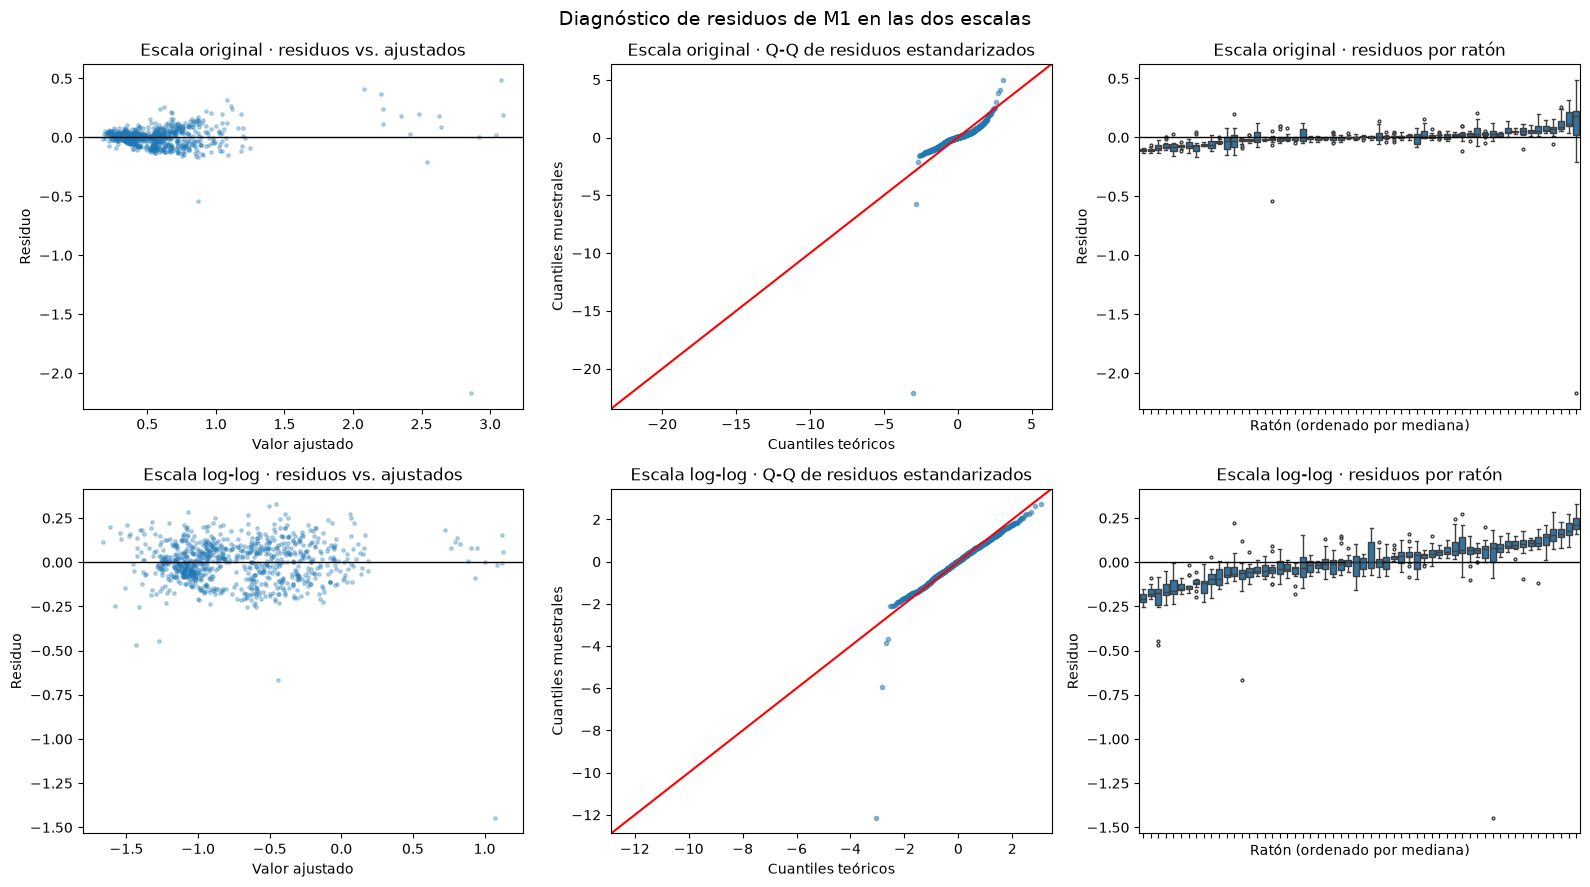

In [9]:
# Diagnóstico de residuos de M1 en las dos escalas: una fila por escala
modelos_m1 = {"Escala original": m1_raton, "Escala log-log": m1_log}

fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for fila, (escala, modelo) in zip(axs, modelos_m1.items()):
    estandarizados = modelo.get_influence().resid_studentized_internal

    # Linealidad y homocedasticidad: sin patrón y con dispersión constante alrededor de 0
    fila[0].scatter(modelo.fittedvalues, modelo.resid, s=6, alpha=0.3)
    fila[0].axhline(0, color="black", linewidth=1)
    fila[0].set(title=f"{escala} · residuos vs. ajustados", xlabel="Valor ajustado", ylabel="Residuo")

    # Normalidad: puntos sobre la diagonal
    sm.qqplot(estandarizados, line="45", ax=fila[1], markersize=3, alpha=0.5)
    fila[1].set(title=f"{escala} · Q-Q de residuos estandarizados", xlabel="Cuantiles teóricos",
                ylabel="Cuantiles muestrales")

    # Independencia: residuos agrupados por ratón, ordenados por su mediana
    por_raton = pd.DataFrame({"residuo": modelo.resid, "raton": grupos_train})
    orden = por_raton.groupby("raton")["residuo"].median().sort_values().index
    sns.boxplot(data=por_raton, x="raton", y="residuo", order=orden, ax=fila[2], fliersize=2)
    fila[2].axhline(0, color="black", linewidth=1)
    fila[2].set(title=f"{escala} · residuos por ratón", xlabel="Ratón (ordenado por mediana)", ylabel="Residuo")
    fila[2].tick_params(axis="x", labelbottom=False)

fig.suptitle("Diagnóstico de residuos de M1 en las dos escalas", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURAS / "m1_supuestos_escalas.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
def pruebas_supuestos(modelo, grupos):
    """Breusch-Pagan, Jarque-Bera, Durbin-Watson (filas ordenadas por ratón) y varianza residual entre ratones."""
    residuos = modelo.resid
    _, p_bp, _, _ = het_breuschpagan(residuos, modelo.model.exog)
    _, p_jb, asimetria, curtosis = jarque_bera(residuos)
    orden_raton = grupos.sort_values(kind="stable").index
    return pd.Series({
        "Breusch-Pagan (p)": p_bp,
        "Jarque-Bera (p)": p_jb,
        "Asimetría de residuos": asimetria,
        "Curtosis de residuos": curtosis,
        "Durbin-Watson": durbin_watson(residuos.loc[orden_raton]),
        "Varianza residual entre ratones": residuos.groupby(grupos).transform("mean").var() / residuos.var(),
    })


comparacion_supuestos = pd.DataFrame(
    {escala: pruebas_supuestos(modelo, grupos_train) for escala, modelo in modelos_m1.items()}).round(3)
comparacion_supuestos

,Escala original,Escala log-log
Breusch-Pagan (p),0.000,0.000
Jarque-Bera (p),0.000,0.000
Asimetría de residuos,-10.562,-2.196
Curtosis de residuos,230.691,26.427
Durbin-Watson,1.653,0.753
Varianza residual entre ratones,0.238,0.618


**Interpretación:** en la escala original, los residuos no cumplen la normalidad ni la homocedasticidad: unas pocas
réplicas tienen residuos enormes (hasta −2,2), la curtosis es de 231 y el gráfico Q-Q se aleja por completo de la
diagonal en las colas. En escala log-log, la curtosis baja a 26 y la asimetría de −10,6 a −2,2, de modo que la
mayoría de los residuos sigue la diagonal y solo quedan unas pocas réplicas extremas. Aun así, las pruebas de
Breusch-Pagan y Jarque-Bera rechazan sus hipótesis nulas en las dos escalas, lo que es esperable con 867 réplicas,
porque con muestras grandes estas pruebas detectan desviaciones pequeñas; por eso la decisión se apoya en la magnitud
de la desviación y no solo en el valor p.

Por otra parte, la independencia no se cumple en ninguna escala, y en log-log se ve con más claridad: el
Durbin-Watson baja a 0,75 y el 62 % de la varianza residual está entre ratones, como muestra el panel de residuos por
ratón, donde cada animal tiene su propio nivel. Esto no es un defecto de la transformación, sino la estructura de
réplicas que, una vez reducido el peso de los valores extremos, queda a la vista. En consecuencia, la falta de
independencia no se corrige transformando, sino con los errores estándar agrupados de la sección 4.1 y con la
validación por ratón.

### 4.3 Influencia y puntos atípicos

¿Hay réplicas o ratones que, por sí solos, determinan los coeficientes? Se usa la distancia de Cook, que combina el
apalancamiento y el residuo de cada réplica (Cook, 1977), con el umbral habitual de 4/n, y luego se mide cuánto
cambian los coeficientes al ajustar el modelo sin el ratón 3484, identificado como excepcional en la Actividad 1.

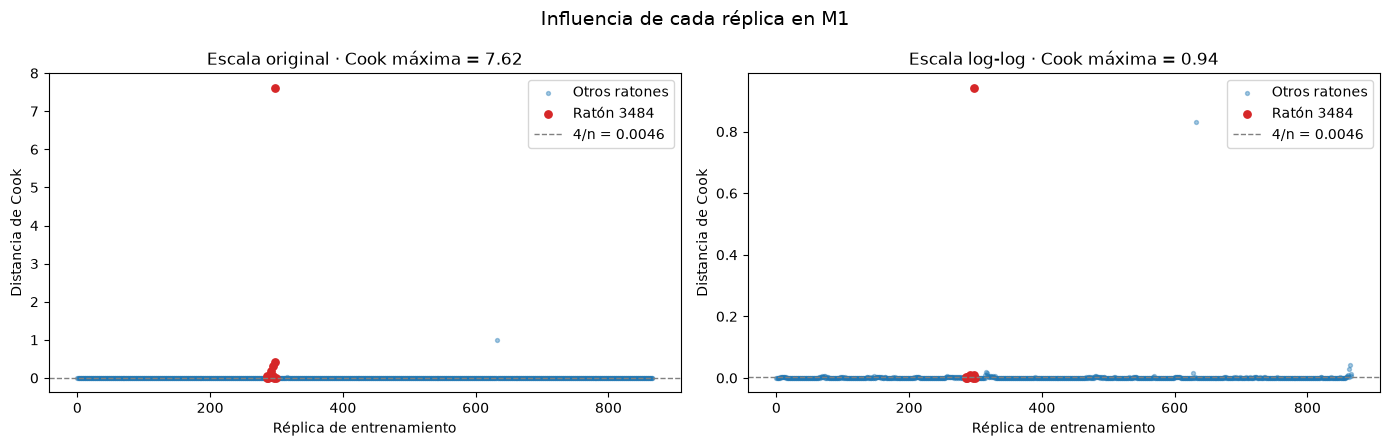

,Escala original,Escala log-log
Cook máxima,7.62,0.94
Réplicas sobre 4/n,21.00,31.00
"De ellas, del ratón 3484",12.00,4.00
Ratones con alguna réplica sobre 4/n,6.00,11.00


In [11]:
# Distancia de Cook de cada réplica en las dos escalas; se resalta el ratón 3484
n, p = int(m1_raton.nobs), int(m1_raton.df_model) + 1
umbral_cook = 4 / n
es_3484 = (train[GRUPO] == "3484").to_numpy()
cook = {escala: modelo.get_influence().cooks_distance[0] for escala, modelo in modelos_m1.items()}

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (escala, valores) in zip(axs, cook.items()):
    posicion = np.arange(n)
    ax.scatter(posicion[~es_3484], valores[~es_3484], s=8, alpha=0.4, label="Otros ratones")
    ax.scatter(posicion[es_3484], valores[es_3484], s=28, color="tab:red", label="Ratón 3484")
    ax.axhline(umbral_cook, color="gray", linestyle="--", linewidth=1, label=f"4/n = {umbral_cook:.4f}")
    ax.set(title=f"{escala} · Cook máxima = {valores.max():.2f}", xlabel="Réplica de entrenamiento",
           ylabel="Distancia de Cook")
    ax.legend()
fig.suptitle("Influencia de cada réplica en M1", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURAS / "m1_cook_escalas.png", dpi=150, bbox_inches="tight")
plt.show()

resumen_cook = pd.DataFrame({
    escala: {
        "Cook máxima": valores.max(),
        "Réplicas sobre 4/n": int((valores > umbral_cook).sum()),
        "De ellas, del ratón 3484": int((valores[es_3484] > umbral_cook).sum()),
        "Ratones con alguna réplica sobre 4/n": train.loc[valores > umbral_cook, GRUPO].nunique(),
    }
    for escala, valores in cook.items()
}).round(2)
resumen_cook

In [12]:
# Sensibilidad: cuánto cambia cada coeficiente al ajustar M1 sin el ratón 3484 (no se elimina del análisis)
train_sin = train[train[GRUPO] != "3484"]
agrupado_sin = dict(cov_type="cluster", cov_kwds={"groups": train_sin[GRUPO]}, use_t=True)
sin_3484 = {
    "Escala original": smf.ols(formula, data=train_sin).fit(**agrupado_sin),
    "Escala log-log": smf.ols(formula_log, data=train_sin).fit(**agrupado_sin),
}

sensibilidad = pd.concat({
    escala: pd.DataFrame({
        "coef_con": modelos_m1[escala].params,
        "coef_sin": sin_3484[escala].params,
        "cambio_%": 100 * (sin_3484[escala].params / modelos_m1[escala].params - 1),
        "p_con": modelos_m1[escala].pvalues,
        "p_sin": sin_3484[escala].pvalues,
    }).drop(index="Intercept")
    for escala in modelos_m1
}).round(3)
sensibilidad

coef_con  coef_sin  cambio_%  p_con  \
Escala original C(Genotype)[T.Ts65Dn]     -0.052    -0.062    19.707  0.004   
                C(Treatment)[T.Saline]    -0.016    -0.017     8.541  0.247   
                C(Behavior)[T.S/C]        -0.096    -0.089    -7.292  0.000   
                DYRK1A_N                   0.847     0.563   -33.579  0.003   
                BRAF_N                     0.321     0.408    26.927  0.011   
                ITSN1_N                    0.097     0.345   254.757  0.668   
Escala log-log  C(Genotype)[T.Ts65Dn]     -0.114    -0.121     6.504  0.000   
                C(Treatment)[T.Saline]    -0.045    -0.042    -6.023  0.079   
                C(Behavior)[T.S/C]        -0.215    -0.205    -4.650  0.000   
                np.log(DYRK1A_N)           0.551     0.531    -3.606  0.000   
                np.log(BRAF_N)             0.196     0.213     8.924  0.014   
                np.log(ITSN1_N)            0.232     0.272    17.288  0.062   

                                        p_sin  
Escala original C(Genotype)[T.Ts65Dn]   0.000  
                C(Treatment)[T.Saline]  0.190  
                C(Behavior)[T.S/C]      0.000  
                DYRK1A_N                0.008  
                BRAF_N                  0.002  
                ITSN1_N                 0.006  
Escala log-log  C(Genotype)[T.Ts65Dn]   0.000  
                C(Treatment)[T.Saline]  0.108  
                C(Behavior)[T.S/C]      0.000  
                np.log(DYRK1A_N)        0.000  
                np.log(BRAF_N)          0.012  
                np.log(ITSN1_N)         0.025

**Interpretación:** en la escala original, una sola réplica del ratón 3484 alcanza una distancia de Cook de 7,62,
muy por encima de cualquier otra, y 12 de las 21 réplicas sobre el umbral pertenecen a ese animal. Su efecto se
confirma en la sensibilidad: al ajustar sin él, el coeficiente de `DYRK1A_N` cae un 34 %, el de `BRAF_N` sube un 27 %
y el de `ITSN1_N` se multiplica por más de tres y pasa de no ser significativo (p = 0,668) a serlo (p = 0,006). Es
decir, en esa escala las conclusiones dependían de un solo ratón.

En cambio, en log-log la distancia de Cook máxima baja a 0,94 y la influencia se reparte: hay más réplicas sobre el
umbral (31), pero pertenecen a 11 ratones distintos y solo 4 son del 3484. Además, al quitar ese ratón, los
coeficientes cambian entre un 4 % y un 17 %, y ninguna conclusión se invierte. Por lo tanto, la transformación
logarítmica permitió conservar al ratón 3484, como se decidió en la Actividad 1, sin que domine el modelo. Eliminar un
animal por ser extremo habría sido una decisión más fácil, pero menos defendible, porque sus valores son reales y
reproducibles en sus réplicas.

### 4.4 Multicolinealidad

El factor de inflación de la varianza (VIF) indica cuánto aumenta la varianza de un coeficiente porque su predictor
se puede reconstruir a partir de los demás; un valor mayor que 10 suele considerarse problemático (James et al.,
2023).

In [13]:
# VIF de los predictores de M1 en las dos escalas (matriz de diseño con intercepto)
def calcular_vif(modelo):
    matriz, nombres = modelo.model.exog, modelo.model.exog_names
    return pd.Series([variance_inflation_factor(matriz, i) for i in range(1, matriz.shape[1])],
                     index=[n[7:-1] if n.startswith("np.log(") else n for n in nombres[1:]])


vif = pd.DataFrame({escala: calcular_vif(modelo) for escala, modelo in modelos_m1.items()}).round(2)
vif

,Escala original,Escala log-log
C(Genotype)[T.Ts65Dn],1.15,1.15
C(Treatment)[T.Saline],1.01,1.01
C(Behavior)[T.S/C],1.32,1.94
DYRK1A_N,27.12,18.15
BRAF_N,14.30,6.53
ITSN1_N,14.19,10.80


**Interpretación:** en la escala original, las tres proteínas superan el umbral de 10 (`DYRK1A_N` = 27,1,
`BRAF_N` = 14,3 e `ITSN1_N` = 14,2). En log-log los valores bajan, aunque `DYRK1A_N` (18,2) e `ITSN1_N` (10,8) siguen
por encima, lo que concuerda con sus correlaciones de la sección 3. Esta colinealidad no afecta la capacidad de
predecir, pero sí vuelve imprecisos los coeficientes individuales: explica que `ITSN1_N` tenga el error estándar más
amplio y que su efecto no se pueda separar del de `DYRK1A_N`. Por eso no se eliminaron proteínas, sino que la
colinealidad se atendió con regularización en el modelo predictivo: Elastic Net reparte el peso entre los predictores
correlacionados en lugar de elegir uno al azar (Zou & Hastie, 2005).

### 4.5 Desempeño predictivo y dónde falla

Por último, se reajustan los dos modelos finales de la Actividad 2 con los hiperparámetros ya elegidos: M1 en log-log
y M2 Elastic Net (α = 0,0144 y `l1_ratio` = 0,1). Primero se revisa el RMSE en cada pliegue de la validación agrupada
por ratón y luego el desempeño en los 14 ratones de prueba, en la escala original de `pERK_N`.

In [14]:
# Modelos finales de la Actividad 2, con los hiperparámetros que eligió su búsqueda (sección 5 de ese notebook)
prep_m1 = ColumnTransformer([
    ("num", FunctionTransformer(np.log, feature_names_out="one-to-one"), PREDICTORES_M1),
    ("cat", OneHotEncoder(drop="if_binary"), DISENO),
], verbose_feature_names_out=False)

prep_m2 = ColumnTransformer([
    ("num", Pipeline([
        ("log", FunctionTransformer(np.log, feature_names_out="one-to-one")),
        ("escala", StandardScaler()),
        ("imputa", KNNImputer()),
    ]), PROTEINAS_M2),
    ("cat", OneHotEncoder(drop="if_binary"), DISENO),
], verbose_feature_names_out=False)

ALPHA_ENET = np.logspace(-5, -1, 20)[15]      # 0,01438: valor de la grilla elegido en la Actividad 2
m1_final = TransformedTargetRegressor(
    regressor=Pipeline([("prep", prep_m1), ("modelo", LinearRegression())]),
    func=np.log, inverse_func=np.exp)
enet_final = TransformedTargetRegressor(
    regressor=Pipeline([("prep", prep_m2), ("modelo", ElasticNet(alpha=ALPHA_ENET, l1_ratio=0.1, max_iter=50_000))]),
    func=np.log, inverse_func=np.exp)

X_reg = {"M1 log-log": PREDICTORES_M1 + DISENO, "M2 Elastic Net": PROTEINAS_M2 + DISENO}
regresores = {"M1 log-log": m1_final, "M2 Elastic Net": enet_final}
y_train_reg, y_test_reg = train[OBJETIVO_REG], test[OBJETIVO_REG]

# RMSE de validación en cada pliegue, con la misma validación agrupada de la Actividad 2
cv_reg = GroupKFold(n_splits=5)
pliegue_3484 = next(i for i, (_, val) in enumerate(cv_reg.split(train, groups=grupos_train), start=1)
                    if "3484" in set(grupos_train.iloc[val]))
rmse_pliegues = pd.DataFrame({
    nombre: -cross_validate(modelo, train[X_reg[nombre]], y_train_reg, groups=grupos_train, cv=cv_reg,
                            scoring="neg_root_mean_squared_error")["test_score"]
    for nombre, modelo in regresores.items()
}, index=[f"Pliegue {i}" for i in range(1, 6)]).round(3)
print(f"El ratón 3484 queda en la validación del pliegue {pliegue_3484}")
rmse_pliegues

El ratón 3484 queda en la validación del pliegue 1


,M1 log-log,M2 Elastic Net
Pliegue 1,0.195,0.201
Pliegue 2,0.081,0.045
Pliegue 3,0.075,0.046
Pliegue 4,0.060,0.029
Pliegue 5,0.064,0.045


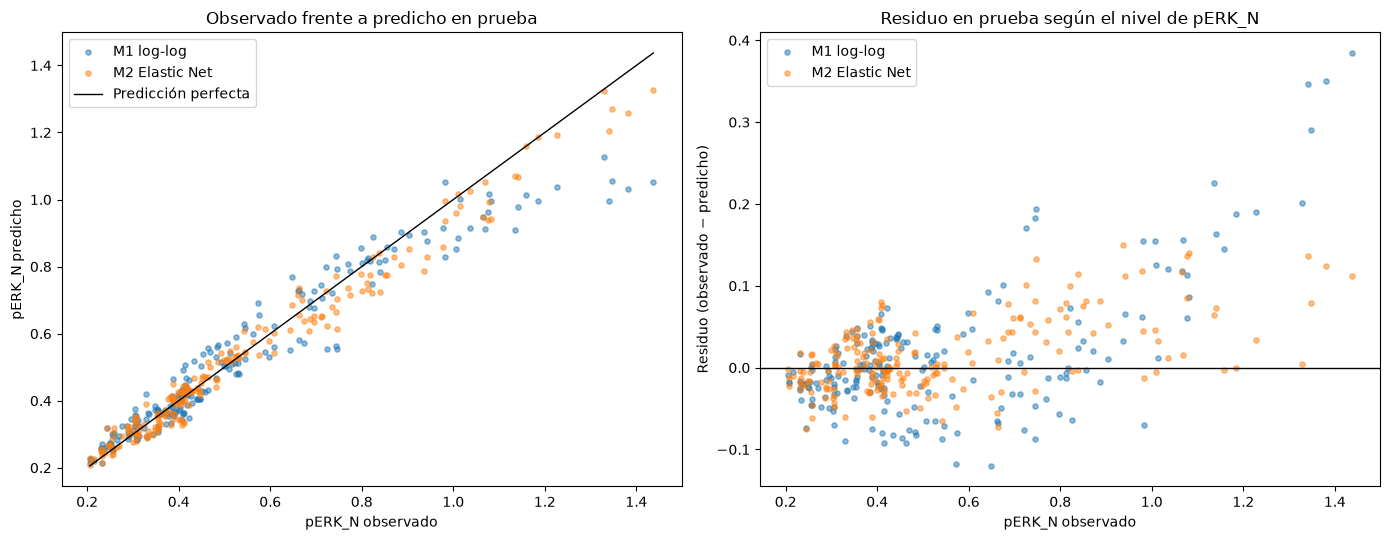

,R2,RMSE,MAE
Línea base,-0.004,0.273,0.223
M1 log-log,0.919,0.078,0.050
M2 Elastic Net,0.972,0.046,0.033


,M1 log-log,M2 Elastic Net
pERK_N,,
Tercio bajo,-0.013,-0.004
Tercio medio,-0.003,-0.001
Tercio alto,0.053,0.044


In [15]:
# Desempeño en prueba, en la escala original de pERK_N
predicciones = {"Línea base": pd.Series(y_train_reg.mean(), index=y_test_reg.index)}
for nombre, modelo in regresores.items():
    modelo.fit(train[X_reg[nombre]], y_train_reg)
    predicciones[nombre] = pd.Series(modelo.predict(test[X_reg[nombre]]), index=y_test_reg.index)

tabla_prueba_reg = pd.DataFrame({
    nombre: {
        "R2": r2_score(y_test_reg, pred),
        "RMSE": root_mean_squared_error(y_test_reg, pred),
        "MAE": mean_absolute_error(y_test_reg, pred),
    }
    for nombre, pred in predicciones.items()
}).T.round(3)

# Observado frente a predicho, y residuo de prueba según el nivel de pERK_N
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
limites = [y_test_reg.min(), y_test_reg.max()]
for nombre in regresores:
    axs[0].scatter(y_test_reg, predicciones[nombre], s=14, alpha=0.5, label=nombre)
    axs[1].scatter(y_test_reg, y_test_reg - predicciones[nombre], s=14, alpha=0.5, label=nombre)
axs[0].plot(limites, limites, color="black", linewidth=1, label="Predicción perfecta")
axs[0].set(title="Observado frente a predicho en prueba", xlabel="pERK_N observado", ylabel="pERK_N predicho")
axs[1].axhline(0, color="black", linewidth=1)
axs[1].set(title="Residuo en prueba según el nivel de pERK_N", xlabel="pERK_N observado",
           ylabel="Residuo (observado − predicho)")
for ax in axs:
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / "regresion_prueba.png", dpi=150, bbox_inches="tight")
plt.show()

# Sesgo según el nivel: residuo medio del tercio inferior y del tercio superior de pERK_N observado
tercio = pd.qcut(y_test_reg, 3, labels=["Tercio bajo", "Tercio medio", "Tercio alto"])
sesgo_nivel = pd.DataFrame({nombre: (y_test_reg - predicciones[nombre]).groupby(tercio, observed=True).mean()
                            for nombre in regresores}).round(3)
display(tabla_prueba_reg)
sesgo_nivel

**Interpretación:** en prueba, Elastic Net alcanza un R² de 0,972 y un RMSE de 0,046, frente a 0,919 y 0,078 de M1
y a un RMSE de 0,273 de la línea base. Este desempeño no se debe a una fuga de información: la partición es por
ratón, todo el preprocesamiento está dentro del `Pipeline` y la prueba no intervino en ninguna decisión. Se explica
porque `pERK_N` pertenece a una cascada de señalización cuyas demás proteínas también se midieron, de modo que el
modelo predice una proteína a partir de sus vecinas en la misma vía.

Sin embargo, el diagnóstico muestra dos condiciones en las que el modelo falla. Primero, en la validación, el RMSE del
pliegue 1 (0,195 en M1 y 0,201 en Elastic Net) es entre dos y siete veces mayor que el de los demás pliegues,
porque en ese pliegue queda el ratón 3484: ningún modelo predice bien a un animal con valores fuera del rango de los
que vio al entrenar. Segundo, los dos modelos subestiman los valores altos: en el tercio superior de `pERK_N`, el
residuo medio es de 0,044 en Elastic Net y de 0,053 en M1, mientras que en los otros dos tercios es cercano a 0. Este
sesgo es una consecuencia conocida de la regularización, que encoge las predicciones hacia la media (James et al.,
2023), y de ajustar en escala logarítmica. En consecuencia, el modelo es confiable para ratones con niveles típicos de
`pERK_N`, pero no para identificar ni cuantificar a los animales con niveles excepcionalmente altos, que pueden ser
justamente los de mayor interés biológico.

### 4.6 Balance del diagnóstico de la regresión

| Aspecto | Resultado | Cómo se atendió | Qué queda pendiente |
|---|---|---|---|
| Linealidad | Se cumple en las dos escalas | — | — |
| Normalidad | No se cumple; mejora mucho en log-log (curtosis de 231 a 26) | Escala log-log | Colas pesadas por unas pocas réplicas |
| Homocedasticidad | No se cumple en ninguna escala | Errores estándar robustos agrupados | — |
| Independencia | No se cumple: el 62 % de la varianza residual está entre ratones | Errores agrupados y validación por ratón | Un modelo mixto con efecto aleatorio por ratón la modelaría de forma explícita |
| Influencia | Un ratón dominaba el modelo (Cook de 7,62) | Escala log-log (Cook de 0,94), sin eliminarlo | El ratón 3484 sigue siendo mal predicho |
| Multicolinealidad | VIF de 14 a 27 en las proteínas de M1 | Regularización en M2 | Los coeficientes de M1 no separan `DYRK1A_N` de `ITSN1_N` |

En resumen, M1 en log-log con errores agrupados es un modelo adecuado para explicar, siempre que sus coeficientes se
lean como asociaciones y con la incertidumbre correcta; y Elastic Net es adecuado para predecir dentro del rango de
los datos.

## 5. Diagnóstico del modelo de clasificación

### 5.1 El costo de ignorar la dependencia entre réplicas

El modelo final de la Actividad 3 es una SVM con kernel RBF (Cortes & Vapnik, 1995), elegida entre seis clasificadores
por su desempeño por ratón y por ser la que menos se equivoca en el genotipo. Antes de evaluarla, se repite con ella
la comparación central del proyecto: el mismo modelo y los mismos datos, validados repartiendo las réplicas por filas
o por ratón.

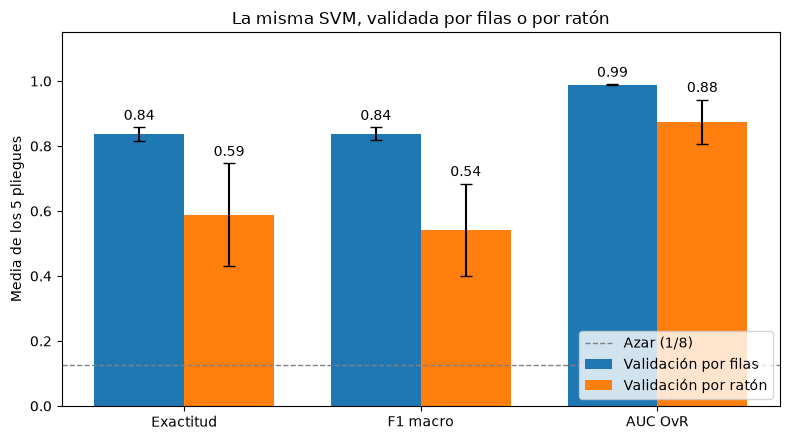

,Exactitud,F1 macro,AUC OvR
Por filas,0.836 ± 0.021,0.838 ± 0.020,0.989 ± 0.001
Por ratón,0.589 ± 0.158,0.542 ± 0.142,0.875 ± 0.068


In [16]:
# Modelo final de la Actividad 3: SVM con kernel RBF y los hiperparámetros que eligió su búsqueda
def crear_pipeline(modelo):
    """Pipeline completo; cada paso se ajusta solo con los datos de entrenamiento de cada pliegue."""
    return Pipeline([
        ("log", FunctionTransformer(np.log, feature_names_out="one-to-one")),
        ("escala", StandardScaler()),
        ("imputa", KNNImputer()),
        ("modelo", modelo),
    ])


svm_final = crear_pipeline(SVC(kernel="rbf", C=100, gamma=1e-5, class_weight="balanced",
                               probability=True, random_state=SEMILLA))
X_train, y_train = train[PROTEINAS], train[OBJETIVO_CLA]
X_test, y_test = test[PROTEINAS], test[OBJETIVO_CLA]

# La misma SVM validada de dos formas: repartiendo por filas o por ratón
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_filas = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_fuga = {"Exactitud": "accuracy", "F1 macro": "f1_macro", "AUC OvR": "roc_auc_ovr"}

fuga = {}
for esquema, validacion in {"Por filas": cv_filas, "Por ratón": cv}.items():
    r = cross_validate(svm_final, X_train, y_train, cv=validacion, scoring=metricas_fuga, n_jobs=-1,
                       groups=grupos_train if esquema == "Por ratón" else None)
    fuga[esquema] = {m: r[f"test_{m}"] for m in metricas_fuga}

tabla_fuga = pd.DataFrame({esquema: {m: f"{v.mean():.3f} ± {v.std():.3f}" for m, v in valores.items()}
                           for esquema, valores in fuga.items()}).T

fig, ax = plt.subplots(figsize=(8, 4.5))
ancho = 0.38
for i, (esquema, valores) in enumerate(fuga.items()):
    medias = [v.mean() for v in valores.values()]
    desviaciones = [v.std() for v in valores.values()]
    barras = ax.bar(np.arange(len(medias)) + (i - 0.5) * ancho, medias, ancho, yerr=desviaciones,
                    capsize=4, label=f"Validación {esquema.lower()}")
    ax.bar_label(barras, fmt="%.2f", padding=3)
ax.axhline(1 / len(CLASES), color="gray", linestyle="--", linewidth=1, label="Azar (1/8)")
ax.set_xticks(np.arange(len(metricas_fuga)), list(metricas_fuga))
ax.set(title="La misma SVM, validada por filas o por ratón", ylabel="Media de los 5 pliegues", ylim=(0, 1.15))
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURAS / "fuga_filas_raton.png", dpi=150, bbox_inches="tight")
plt.show()
tabla_fuga

**Interpretación:** validada por filas, la SVM parece un clasificador excelente, con una exactitud de 0,836 y un AUC
de 0,989. Validada por ratón, su exactitud es de 0,589 y su AUC de 0,875. La diferencia de 25 puntos de exactitud no
viene del modelo ni de los datos, que son los mismos, sino de la forma de evaluar: al repartir por filas, las réplicas
de un ratón quedan en entrenamiento y en validación a la vez, y el modelo acierta porque reconoce al individuo
(Roberts et al., 2017). En la Actividad 3, la misma comparación con una regresión logística dio 0,991 frente a 0,559;
la SVM se infla menos porque sus hiperparámetros la hacen más rígida, pero el sesgo sigue siendo grande.

Además, la validación por filas subestima la incertidumbre: su desviación entre pliegues es de ± 0,021, frente a
± 0,158 por ratón. Así, la evaluación incorrecta no solo reporta un desempeño más alto, sino que lo reporta con una
seguridad aparente mucho mayor. Este es el equivalente, en clasificación, de los valores p inflados de la
sección 4.1.

### 5.2 Desempeño general

El desempeño se mide de dos maneras complementarias. En la validación, cada réplica de entrenamiento recibe la
probabilidad de un modelo que no vio a su ratón (predicciones fuera de pliegue); en la prueba, el modelo ajustado con
todo el entrenamiento predice los 14 ratones que se reservaron desde el inicio. En ambos casos se reportan las
métricas por réplica y la exactitud por ratón, que resulta de promediar las probabilidades de las réplicas de cada
animal.

In [17]:
def metricas_desde_proba(y, proba):
    """Métricas de clasificación calculadas a partir de probabilidades, sobre todas las réplicas."""
    pred = np.array(CLASES)[proba.argmax(axis=1)]
    return pd.Series({
        "Exactitud": accuracy_score(y, pred),
        "Exactitud balanceada": balanced_accuracy_score(y, pred),
        "F1 macro": f1_score(y, pred, average="macro", zero_division=0),
        "AUC OvR": roc_auc_score(y, proba, multi_class="ovr", labels=CLASES),
        "Log loss": log_loss(y, proba, labels=CLASES),
        "Brier": brier_score_loss(y, proba, labels=CLASES),
    })


def clasificar_por_raton(proba, y, grupos):
    """Promedia las probabilidades de las réplicas de cada ratón y le asigna la clase más probable."""
    promedio = pd.DataFrame(proba, columns=CLASES, index=y.index).groupby(grupos.to_numpy()).mean()
    real = y.groupby(grupos.to_numpy()).first().loc[promedio.index].astype(str)
    return real, promedio.idxmax(axis=1), promedio.max(axis=1)


# Validación: probabilidades fuera de pliegue (cada réplica la predice un modelo que no vio a su ratón)
proba_cv = cross_val_predict(svm_final, X_train, y_train, groups=grupos_train, cv=cv,
                             method="predict_proba", n_jobs=-1)
# Prueba: modelo ajustado con todo el entrenamiento
svm_final.fit(X_train, y_train)
assert list(svm_final.classes_) == CLASES
proba_test = svm_final.predict_proba(X_test)
proba_base = DummyClassifier(strategy="prior").fit(X_train, y_train).predict_proba(X_test)

real_cv, pred_cv, confianza_cv = clasificar_por_raton(proba_cv, y_train, grupos_train)
real_test, pred_test, confianza_test = clasificar_por_raton(proba_test, y_test, grupos_test)

desempeno = pd.DataFrame({
    "Validación (fuera de pliegue)": metricas_desde_proba(y_train, proba_cv),
    "Prueba": metricas_desde_proba(y_test, proba_test),
    "Línea base en prueba": metricas_desde_proba(y_test, proba_base),
}).T
desempeno["Exactitud por ratón"] = [accuracy_score(real_cv, pred_cv), accuracy_score(real_test, pred_test), np.nan]
desempeno["Ratones bien clasificados"] = [f"{(real_cv == pred_cv).sum()} de {len(real_cv)}",
                                          f"{(real_test == pred_test).sum()} de {len(real_test)}", "—"]
desempeno.round(3)

,Exactitud,Exactitud balanceada,F1 macro,AUC OvR,Log loss,Brier,Exactitud por ratón,Ratones bien clasificados
Validación (fuera de pliegue),0.557,0.551,0.536,0.854,1.480,0.651,0.621,36 de 58
Prueba,0.676,0.650,0.598,0.929,0.977,0.522,0.714,10 de 14
Línea base en prueba,0.143,0.125,0.031,0.500,2.079,0.875,NaN,—


**Interpretación:** la SVM supera con amplitud a la línea base: en prueba, su exactitud es de 0,676 frente a 0,143,
su F1 macro de 0,598 frente a 0,031 y su AUC de 0,929 frente a 0,5. A nivel de ratón, clasifica bien 36 de 58 en la
validación (62 %) y 10 de 14 en la prueba (71 %), unas cinco veces más que el azar para 8 clases. Las métricas de
prueba son algo mejores que las de validación, pero la diferencia es compatible con el tamaño de la prueba, donde un
solo ratón cambia la exactitud en 7 puntos, de modo que no indica un desempeño real superior. Vale la pena notar que
el AUC fuera de pliegue (0,854) es menor que la media por pliegue reportada en la Actividad 3 (0,875), porque aquí
todas las réplicas se evalúan juntas y las probabilidades de modelos distintos no son del todo comparables.

En resumen, el modelo aprende una señal real, pero está lejos de ser un clasificador confiable por sí solo: se
equivoca en cerca de cuatro de cada diez ratones nuevos.

### 5.3 Matriz de confusión y curvas ROC

La matriz de confusión se presenta por ratón, que es la unidad de decisión, con las clases ordenadas en cuatro bloques
de genotipo y conducta. Las curvas ROC se trazan uno contra el resto, por réplica.

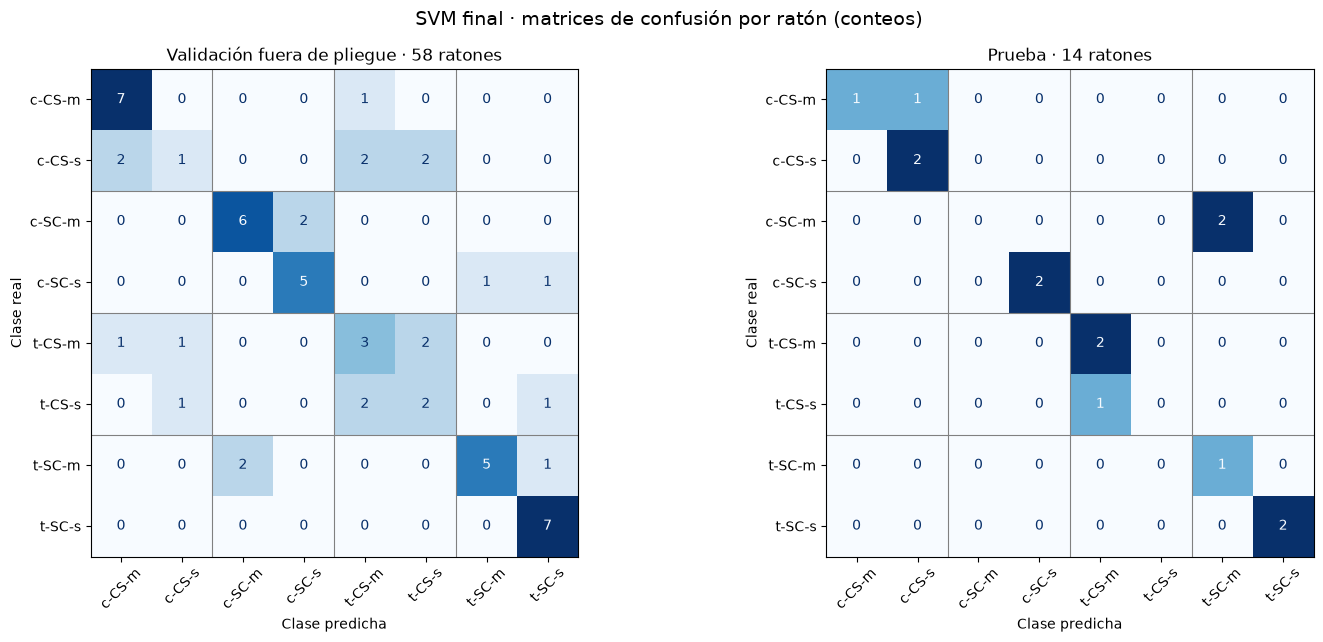

In [18]:
# Matrices de confusión por ratón: validación (58 ratones) y prueba (14 ratones)
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (titulo, real, pred) in zip(axs, [("Validación fuera de pliegue · 58 ratones", real_cv, pred_cv),
                                          ("Prueba · 14 ratones", real_test, pred_test)]):
    ConfusionMatrixDisplay.from_predictions(real, pred, labels=CLASES, cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=titulo, xlabel="Clase predicha", ylabel="Clase real")
    ax.tick_params(axis="x", rotation=45)
    # Líneas que separan los cuatro bloques de genotipo y conducta (c-CS, c-SC, t-CS y t-SC)
    for corte in (1.5, 3.5, 5.5):
        ax.axhline(corte, color="gray", linewidth=0.8)
        ax.axvline(corte, color="gray", linewidth=0.8)
fig.suptitle("SVM final · matrices de confusión por ratón (conteos)", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURAS / "confusion_raton.png", dpi=150, bbox_inches="tight")
plt.show()

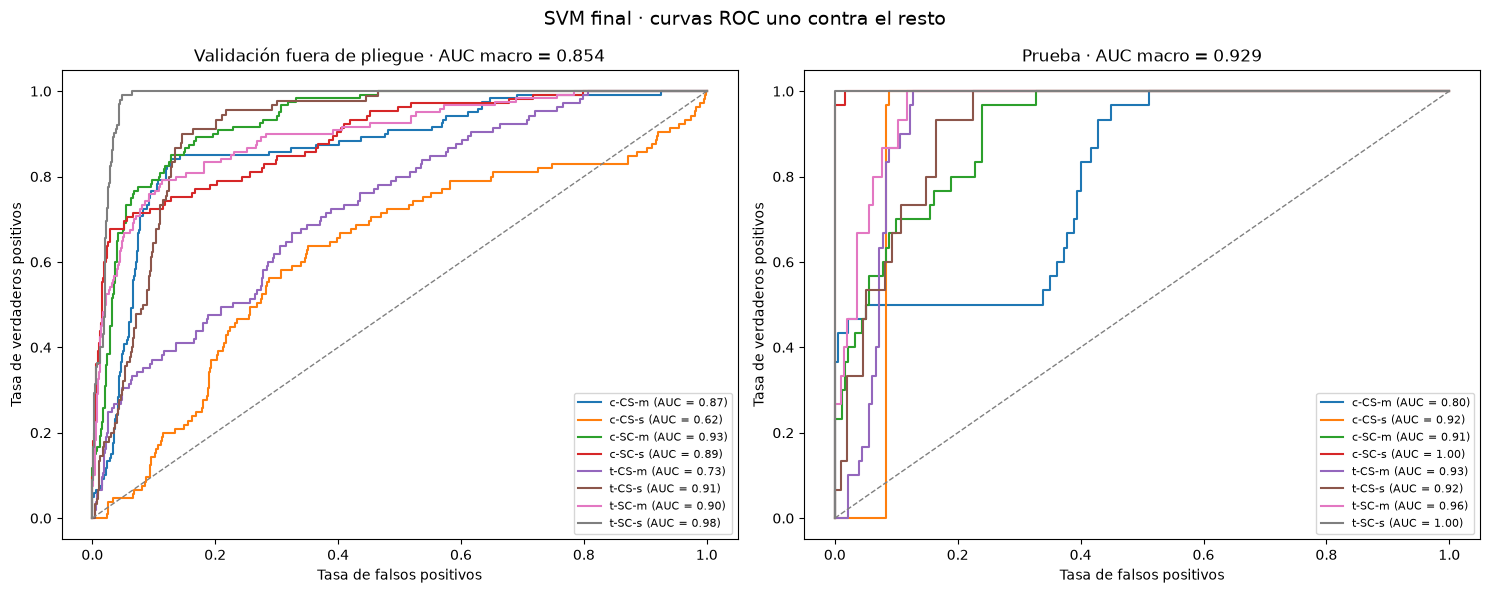

In [19]:
# Curvas ROC uno contra el resto: validación fuera de pliegue y prueba
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, (titulo, y, proba) in zip(axs, [("Validación fuera de pliegue", y_train, proba_cv),
                                        ("Prueba", y_test, proba_test)]):
    y_bin = label_binarize(y, classes=CLASES)
    for k, clase in enumerate(CLASES):
        fpr, tpr, _ = roc_curve(y_bin[:, k], proba[:, k])
        ax.plot(fpr, tpr, label=f"{clase} (AUC = {roc_auc_score(y_bin[:, k], proba[:, k]):.2f})")
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
    macro = roc_auc_score(y, proba, multi_class="ovr", labels=CLASES)
    ax.set(title=f"{titulo} · AUC macro = {macro:.3f}", xlabel="Tasa de falsos positivos",
           ylabel="Tasa de verdaderos positivos")
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("SVM final · curvas ROC uno contra el resto", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURAS / "roc_validacion_prueba.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** las matrices muestran que los errores tienen estructura. En la validación, casi todos los
ratones mal clasificados quedan dentro de su propio grupo de conducta: los ratones CS se confunden con otras clases
CS, y los SC con otras clases SC; solo un ratón cruza de un grupo al otro. Dentro del grupo CS, en cambio, la
confusión es amplia: `c-CS-s` acierta 1 de 7 ratones y los demás se reparten entre `c-CS-m`, `t-CS-m` y `t-CS-s`, y
`t-CS-m` y `t-CS-s` se confunden entre sí. En la prueba se repite el patrón: los cuatro errores están dentro del mismo
grupo de conducta, y dos de ellos son los ratones `c-SC-m` predichos como `t-SC-m`.

Las curvas ROC llevan a una lectura parecida, pero con una advertencia. En la validación, las clases no estimuladas
tienen un AUC alto, mientras que `c-CS-s` y `t-CS-m` tienen los valores más bajos. En la
prueba, el AUC macro sube a 0,929, pero cada clase tiene solo 15 o 30 réplicas positivas, provenientes de uno o dos
ratones, por lo que esas curvas son poco precisas. Además, un AUC alto indica que el modelo ordena bien las
probabilidades, no que clasifique bien: con 8 clases, la clase correcta puede quedar en segundo lugar con frecuencia,
y por eso el AUC de 0,85 convive con una exactitud de 0,56 (Saito & Rehmsmeier, 2015).

### 5.4 Sesgos y patrones de error

Para identificar si el modelo se equivoca de forma sistemática, se revisan tres aspectos: en qué factor del diseño
está cada error, si las clases con menos ratones se clasifican peor, y si el modelo asigna menos confianza a los
ratones en los que se equivoca.

In [20]:
def errores_por_factor(real, pred):
    """Proporción de ratones cuyo error está en el genotipo, la conducta o el tratamiento (clase 'g-CC-t')."""
    real, pred = real.str.split("-", expand=True), pred.str.split("-", expand=True)
    return pd.Series({
        "Genotipo": (real[0] != pred[0]).mean(),
        "Conducta": (real[1] != pred[1]).mean(),
        "Tratamiento": (real[2] != pred[2]).mean(),
    })


# Un ratón puede fallar en más de un factor
tabla_factores = pd.DataFrame({
    "Validación (58 ratones)": errores_por_factor(real_cv, pred_cv),
    "Prueba (14 ratones)": errores_por_factor(real_test, pred_test),
}).T
tabla_factores["Ratones mal clasificados"] = [(real_cv != pred_cv).mean(), (real_test != pred_test).mean()]
tabla_factores.round(3)

,Genotipo,Conducta,Tratamiento,Ratones mal clasificados
Validación (58 ratones),0.207,0.017,0.224,0.379
Prueba (14 ratones),0.143,0.000,0.143,0.286


In [21]:
# ¿El error depende del tamaño de la clase? Recall por ratón de cada clase frente a sus ratones de entrenamiento
por_clase = pd.DataFrame({
    "Ratones en entrenamiento": real_cv.value_counts().reindex(CLASES),
    "Bien clasificados": (real_cv[real_cv == pred_cv]).value_counts().reindex(CLASES, fill_value=0),
})
por_clase["Recall por ratón"] = por_clase["Bien clasificados"] / por_clase["Ratones en entrenamiento"]
por_clase["Clase con la que más se confunde"] = [
    pred_cv[(real_cv == clase) & (pred_cv != clase)].mode().get(0, "—") for clase in CLASES]

# ¿El modelo sabe cuándo se equivoca? Confianza media de los ratones bien y mal clasificados
confianza = pd.DataFrame({
    "Validación": confianza_cv.groupby(real_cv == pred_cv).mean(),
    "Prueba": confianza_test.groupby(real_test == pred_test).mean(),
}).rename(index={True: "Ratones bien clasificados", False: "Ratones mal clasificados"}).round(3)
correlacion_tamano = por_clase["Ratones en entrenamiento"].corr(por_clase["Recall por ratón"], method="spearman")
print(f"Correlación de Spearman entre el tamaño de la clase y su recall: {correlacion_tamano:.2f}")
display(por_clase.round(2))
confianza

Correlación de Spearman entre el tamaño de la clase y su recall: 0.48


,Ratones en entrenamiento,Bien clasificados,Recall por ratón,Clase con la que más se confunde
class,,,,
c-CS-m,8,7,0.88,t-CS-m
c-CS-s,7,1,0.14,c-CS-m
c-SC-m,8,6,0.75,c-SC-s
c-SC-s,7,5,0.71,t-SC-m
t-CS-m,7,3,0.43,t-CS-s
t-CS-s,6,2,0.33,t-CS-m
t-SC-m,8,5,0.62,c-SC-m
t-SC-s,7,7,1.00,—


,Validación,Prueba
Ratones mal clasificados,0.612,0.727
Ratones bien clasificados,0.679,0.683


**Interpretación:** el primer patrón es el factor del error. En la validación, solo el 1,7 % de los ratones (uno)
falla en la conducta, frente al 20,7 % en el genotipo y el 22,4 % en el tratamiento; en la prueba, ningún ratón falla
en la conducta. Es decir, el modelo reconoce casi siempre si un ratón fue estimulado para aprender, pero distingue
mucho peor el genotipo y el tratamiento. Esto sugiere que el condicionamiento deja la huella más fuerte en las
proteínas, y que los efectos de la trisomía y de la memantina son más sutiles.

El segundo patrón es la desigualdad entre clases. El recall por ratón va de 1,00 en `t-SC-s` y 0,88 en `c-CS-m` a
0,14 en `c-CS-s` y 0,33 en `t-CS-s`. La correlación entre el tamaño de la clase y su recall es de 0,48, pero con solo
8 clases no permite concluir que el tamaño sea la causa; de hecho, `c-CS-s` tiene 7 ratones y es la peor, mientras que
`t-SC-s`, también con 7, es la mejor. Aun así, las dos clases con peor desempeño son las de mayor interés: `c-CS-s` es
el aprendizaje normal sin fármaco y `t-CS-s` es el aprendizaje fallido (Ahmed et al., 2015). Por lo tanto, el modelo
es menos confiable justo donde la pregunta biológica es más relevante, y además `t-CS-s` se confunde sobre todo con
`t-CS-m`, de modo que un ratón que no aprendió puede clasificarse como uno con el aprendizaje rescatado.

El tercer patrón es la confianza. En la validación, el modelo asigna una probabilidad media de 0,68 a los ratones que
clasifica bien y de 0,61 a los que clasifica mal; en la prueba, la confianza de los errores (0,73) es incluso mayor
que la de los aciertos (0,68). En otras palabras, el modelo no distingue cuándo se equivoca, por lo que su
probabilidad no sirve como señal de alerta para descartar las predicciones dudosas.

### 5.5 Balance del diagnóstico de la clasificación

| Aspecto | Resultado | Implicación |
|---|---|---|
| Desempeño general | 62 % de los ratones en validación y 71 % en prueba, frente a 12,5 % del azar | Hay señal real, pero el modelo falla en cerca de cuatro de cada diez ratones |
| Efecto de la validación | Exactitud de 0,84 por filas frente a 0,59 por ratón | Solo la validación por ratón describe el desempeño frente a animales nuevos |
| Matriz de confusión | Los errores quedan dentro del mismo grupo de conducta | El modelo reconoce la conducta; confunde el genotipo y el tratamiento |
| Curva ROC | AUC de 0,85 en validación y 0,93 en prueba | Ordena bien las probabilidades, pero eso no equivale a clasificar bien |
| Clases débiles | `c-CS-s` (1 de 7 ratones) y `t-CS-s` (2 de 6) | Falla en las clases de mayor interés biológico |
| Confianza | Similar en aciertos y en errores | La probabilidad no advierte cuándo desconfiar de una predicción |
| Estabilidad | F1 macro de 0,33 a 0,78 según el pliegue (Actividad 3) | El resultado depende mucho de qué ratones se usan para entrenar |

## 6. Síntesis del proceso analítico

Cada etapa del proyecto dejó una decisión que condicionó la siguiente. La tabla resume ese encadenamiento.

| Etapa | Hallazgo | Decisión | Consecuencia |
|---|---|---|---|
| Exploración (Actividad 1) | Las réplicas de un ratón son casi idénticas (ICC mediano de 0,70) | Conservar `raton` y partir, validar e inferir por individuo | El tamaño real del estudio es de 72 ratones, no de 1.077 filas |
| Exploración (Actividad 1) | Valores extremos reproducibles en un mismo ratón | Conservarlos y medir su influencia | El ratón 3484 se convirtió en la prueba de robustez de la regresión |
| Exploración (Actividad 1) | Proteínas en bloques muy correlacionados | No eliminar proteínas; tratar la colinealidad en el modelo | Dos modelos de regresión: uno para explicar y otro, regularizado, para predecir |
| Regresión (Actividad 2) | Residuos con colas extremas y un ratón dominante en la escala original | Ajustar en escala log-log | Coeficientes estables frente al ratón 3484 |
| Regresión (Actividad 2) | Errores estándar ordinarios entre 2 y 4 veces menores que los agrupados | Inferencia con errores agrupados por ratón | El efecto del tratamiento deja de ser significativo |
| Clasificación (Actividad 3) | Exactitud cercana a 1 por filas y a 0,56 por ratón | Validación agrupada y estratificada en todas las búsquedas | Métricas modestas, pero honestas |
| Clasificación (Actividad 3) | Cinco modelos empatados en F1 macro | Elegir por desempeño por ratón, error en el genotipo y costo de los errores | SVM como modelo final; random forest como alternativa por sus probabilidades |
| Diagnóstico (Actividad 4) | Los modelos fallan en los valores altos de `pERK_N` y en las clases CS | Declarar los usos previstos y no previstos | Los resultados sirven para explorar y proponer hipótesis, no para decidir sobre individuos |

Así, la coherencia del proyecto no está en haber usado muchos modelos, sino en que la misma pregunta —cuál es la
unidad de análisis— se respondió de la misma forma en la limpieza, en la inferencia, en la validación y en la
interpretación.

## 7. Análisis crítico y ético

### 7.1 Limitaciones de los modelos y de la base

1. **Tamaño efectivo pequeño.** Todo el análisis descansa en 72 ratones, unos 6 por clase al entrenar. Por eso el
   desempeño de la clasificación cambia tanto entre pliegues y la prueba, con uno o dos ratones por clase, solo puede
   confirmar tendencias.
2. **Un solo experimento.** Los datos provienen de una cepa, un laboratorio, un tejido y un protocolo (Higuera et al.,
   2015). Ningún resultado se ha validado con ratones de otro experimento, de modo que no se sabe cuánto de lo
   aprendido es propio de este lote.
3. **Supuestos que no se cumplen del todo.** En la regresión, los residuos conservan colas pesadas y no son
   independientes; los errores agrupados corrigen la inferencia, pero un modelo mixto con un efecto aleatorio por
   ratón representaría mejor la estructura de los datos.
4. **Optimismo en la selección.** Los hiperparámetros y el modelo final se eligieron con los mismos pliegues con que
   se reportan las métricas de validación; una validación cruzada anidada daría una estimación más conservadora
   (Varma & Simon, 2006).
5. **Datos faltantes no aleatorios.** Ocho proteínas no se midieron en ninguna réplica de varios ratones. La
   imputación con vecinos cercanos permite usarlas, pero sus valores imputados son estimaciones, no mediciones.

### 7.2 Sesgos y riesgos de mala interpretación

- **Sesgo por pseudorreplicación.** Es el más grave y no está en los datos, sino en la forma de analizarlos: con la
  misma base, la exactitud pasa de 0,84 a 0,59 y el efecto del tratamiento pasa de significativo a no serlo, según se
  respete o no la unidad experimental. Este problema es frecuente en neurociencia (Lazic, 2010), y quien use esta base
  con una partición por filas obtendrá resultados que parecen mejores que los de este proyecto.
- **Asociación leída como causa.** Que `DYRK1A_N` se asocie con `pERK_N`, o que `APP_N` sea la proteína más importante
  para clasificar, no significa que una cause la otra ni que cause el aprendizaje. El diseño experimental asignó el
  tratamiento y la conducta, pero no los niveles de las proteínas.
- **Un individuo que domina.** En la escala original, las conclusiones de la regresión dependían del ratón 3484. Un
  resultado que cambia al quitar un solo animal no debería presentarse como un hallazgo general.
- **Sesgo hacia el centro.** La regresión subestima los valores altos de `pERK_N`, y la clasificación falla más en las
  clases del grupo estimulado. En ambos casos, el modelo es menos confiable en los casos que más interesan.
- **Confianza que no informa.** La SVM asigna probabilidades parecidas a sus aciertos y a sus errores, por lo que una
  probabilidad alta no debe interpretarse como una predicción segura.
- **Métricas que se leen de más.** Un R² de 0,97 o un AUC de 0,93 suenan a modelos casi perfectos. El primero refleja
  que se predice una proteína con sus vecinas de la misma vía, y el segundo convive con cuatro errores en 14 ratones.

### 7.3 Consideraciones éticas

Aunque el proyecto no involucra datos de personas, sí tiene implicaciones éticas. En primer lugar, la investigación
con animales se rige por el principio de reemplazar, reducir y refinar su uso (Russell & Burch, 1959). Un análisis
que exagera lo que los datos muestran va en contra de ese principio, porque puede llevar a otros grupos a diseñar
experimentos, y a usar más animales, para perseguir efectos que no existen; por el contrario, reconocer que el tamaño
real es de 72 individuos permite planear estudios con el número adecuado de ratones.

En segundo lugar, los resultados tocan una condición humana. El ratón Ts65Dn es un modelo del síndrome de Down, y la
memantina es un fármaco de uso clínico, de modo que una comunicación descuidada, como afirmar que «un modelo
identifica el efecto de la memantina con un 99 % de exactitud», podría generar expectativas infundadas en familias y
cuidadores. Este proyecto no aporta ninguna evidencia sobre el efecto del fármaco en personas.

En tercer lugar, la transparencia es parte de la responsabilidad del analista. Por eso se documentaron las decisiones
en una bitácora, se reportaron los resultados que no funcionaron, como la calibración y la regla de costos de la
Actividad 3, y se declaró que la jerarquía de costos entre errores es un juicio del grupo y no un dato. Esta forma de
reportar sigue la propuesta de las fichas de modelo, que piden declarar para qué sirve y para qué no un modelo antes
de ponerlo en manos de otros (Mitchell et al., 2019).

### 7.4 Dónde son útiles los modelos y dónde no

| Los modelos sí pueden respaldar | Los modelos no deben usarse para |
|---|---|
| Explorar qué proteínas distinguen las condiciones del experimento y priorizar cuáles estudiar | Diagnosticar o clasificar individuos fuera de este experimento |
| Proponer hipótesis sobre la relación entre `pERK_N` y su vía de señalización | Afirmar que una proteína causa el aprendizaje o el efecto de la memantina |
| Verificar la consistencia de muestras nuevas del mismo protocolo, por ejemplo, detectar un posible error de etiquetado en la conducta | Decidir si un ratón «aprendió» o si un tratamiento «funcionó» en un animal concreto |
| Estimar `pERK_N` cuando no se midió, dentro del rango típico de los datos | Cuantificar niveles excepcionalmente altos de `pERK_N` |
| Mostrar, como caso de estudio, el efecto de la pseudorreplicación en la inferencia y la validación | Extrapolar a otras cepas, tejidos, especies o a personas sin una nueva validación |

## 8. Conclusión y mensaje para el usuario de los resultados

El proyecto partió de una pregunta biológica y terminó respondiendo también una pregunta metodológica. En lo
biológico, el perfil de proteínas de la corteza sí contiene información sobre la condición experimental: permite
predecir `pERK_N` con un error bajo y clasificar bien a cerca de dos de cada tres ratones, y la señal más clara es la
del condicionamiento, mientras que las del genotipo y del tratamiento son más débiles. En lo metodológico, el
resultado principal es que casi todas las conclusiones cambian según se respete o no la unidad experimental: el
tamaño de la muestra, la significancia del tratamiento, la influencia de un ratón y el desempeño de los
clasificadores.

**¿Qué decisiones puede respaldar este trabajo?** Decisiones de investigación: qué proteínas priorizar, qué hipótesis
vale la pena probar y cómo diseñar y analizar un experimento con réplicas. **¿Qué decisiones no puede respaldar?**
Decisiones sobre individuos o sobre tratamientos, y cualquier afirmación causal o clínica.

**Mensaje final.** Antes de confiar en un modelo, conviene preguntar cuál es la unidad que se quiere generalizar y
verificar que la evaluación se hizo sobre unidades que el modelo no había visto. En esta base, la respuesta honesta
no es «99 % de exactitud», sino «62 % de los ratones nuevos, con una incertidumbre grande», y es esa respuesta la que
permite tomar buenas decisiones.

## Referencias

Ahmed, M. M., Dhanasekaran, A. R., Block, A., Tong, S., Costa, A. C. S., Stasko, M., & Gardiner, K. J. (2015). Protein dynamics associated with failed and rescued learning in the Ts65Dn mouse model of Down syndrome. *PLOS ONE, 10*(3), e0119491. https://doi.org/10.1371/journal.pone.0119491

Breusch, T. S., & Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation. *Econometrica, 47*(5), 1287–1294. https://doi.org/10.2307/1911963

Cameron, A. C., & Miller, D. L. (2015). A practitioner’s guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317–372. https://doi.org/10.3368/jhr.50.2.317

Cook, R. D. (1977). Detection of influential observation in linear regression. *Technometrics, 19*(1), 15–18. https://doi.org/10.1080/00401706.1977.10489493

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018

Durbin, J., & Watson, G. S. (1950). Testing for serial correlation in least squares regression: I. *Biometrika, 37*(3–4), 409–428.

Higuera, C., Gardiner, K. J., & Cios, K. J. (2015). Self-organizing feature maps identify proteins critical to learning in a mouse model of Down syndrome. *PLOS ONE, 10*(6), e0129126. https://doi.org/10.1371/journal.pone.0129126

Hurlbert, S. H. (1984). Pseudoreplication and the design of ecological field experiments. *Ecological Monographs, 54*(2), 187–211. https://doi.org/10.2307/1942661

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0

Jarque, C. M., & Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2), 163–172. https://doi.org/10.2307/1403192

Kelly, P. A., & Rahmani, Z. (2005). DYRK1A enhances the mitogen-activated protein kinase cascade in PC12 cells by forming a complex with Ras, B-Raf, and MEK1. *Molecular Biology of the Cell, 16*(8), 3562–3573. https://doi.org/10.1091/mbc.e04-12-1085

Kuhn, M., & Johnson, K. (2019). *Feature engineering and selection: A practical approach for predictive models*. CRC Press.

Lazic, S. E. (2010). The problem of pseudoreplication in neuroscientific studies: Is it affecting your analysis? *BMC Neuroscience, 11*, 5. https://doi.org/10.1186/1471-2202-11-5

Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., Spitzer, E., Raji, I. D., & Gebru, T. (2019). Model cards for model reporting. En *Proceedings of the Conference on Fairness, Accountability, and Transparency* (pp. 220–229). ACM. https://doi.org/10.1145/3287560.3287596

Reeves, R. H., Irving, N. G., Moran, T. H., Wohn, A., Kitt, C., Sisodia, S. S., Schmidt, C., Bronson, R. T., & Davisson, M. T. (1995). A mouse model for Down syndrome exhibits learning and behaviour deficits. *Nature Genetics, 11*(2), 177–184. https://doi.org/10.1038/ng1095-177

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Russell, W. M. S., & Burch, R. L. (1959). *The principles of humane experimental technique*. Methuen.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Sweatt, J. D. (2004). Mitogen-activated protein kinases in synaptic plasticity and memory. *Current Opinion in Neurobiology, 14*(3), 311–317. https://doi.org/10.1016/j.conb.2004.04.001

Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, 91. https://doi.org/10.1186/1471-2105-7-91

Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B, 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x